# サンプル&ホールド

入力の電圧を**ある瞬間につかまえて、次の瞬間まで保つ**回路です。出力は階段のようになります。A/D 変換器の前に置いて、変換しているあいだ入力が動かないようにする、という使い方が代表的です。「サンプリング(標本化)」とは、まさにこの「ある瞬間の値を取る」ことです。

この回では、階段になった出力、入力についていく時間のあるトラック&ホールド、そして**エイリアシング**(速い信号が遅い信号に化けて見える現象)を見ます。

## 回路

![サンプル&ホールド](03_sample_hold/circuit.svg)

スイッチ SW が閉じているあいだ、コンデンサ C は入力の電圧まで充電されます。SW を開くと、C は最後の電圧を保ちます。後ろのボルテージフォロワ(0-1)は、C の電荷を逃がさずに電圧を出力へ伝えます。SW はクロック(決まった周期のパルス)で開け閉めします。

## 原理

| 動作 | スイッチ | 出力 |
|---|---|---|
| サンプル&ホールド | 周期ごとに一瞬だけ閉じる | 閉じた瞬間の入力の値を、次の瞬間まで保つ(階段) |
| トラック&ホールド | 周期のうち一部の時間だけ閉じる | 閉じているあいだは入力についていき(トラック)、開くと最後の値を保つ(ホールド) |

1 秒あたりにつかまえる回数を**サンプリング周波数** $f_s$ といいます。入力の 1 周期に何回つかまえるか($f_s / f$)で、階段の細かさが決まります。階段を平均すると、出力は入力より半周期ぶん($1/(2f_s)$)遅れています。

**エイリアシング**:サンプリングでわかるのは「つかまえた瞬間の値」だけです。入力の周波数 $f$ が $f_s$ に近いと、つかまえた値をつないだものは、周波数 $|f - f_s|$ のゆっくりした波に見えます(右の図:$0.9 f_s$ の入力が $0.1 f_s$ に見える)。一般には、$f$ に最も近い $f_s$ の整数倍 $n f_s$ との差 $|f - n f_s|$ に見えます。正しく表すには $f_s > 2f$ が必要で、これを**サンプリング定理**($f_s/2$ を**ナイキスト周波数**)といいます。

![サンプル&ホールドとエイリアシング(模式図)](03_sample_hold/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.sample_hold(freq)` | `mimic.setSampleAndHold(freq)` | SW を閉じる周波数 $f_s$(Hz)。閉じるのは Mimic の 1 サンプル(5 µs)だけ |
| `lab.mimic.track_hold(freq, ratio)` | `mimic.setTrackAndHold(freq, ratio)` | 周期のうち SW を閉じている割合 `ratio`(0〜1) |

- Mimic は 200 kHz(5 µs ごと)で動いているので、周期は 5 µs の整数倍に丸められます。例えば 1100 Hz は 182 サンプル(910 µs)で、1098.9 Hz になります。
- このモードを選んだ直後は、保っている値が中央(2.5 V)から始まります。
- 測定器のオシロ自身も 20 kHz でサンプリングしています。オシロのナイキスト周波数は 10 kHz で、講義で扱う周波数(1 kHz 程度まで)は十分に下です。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.3, mimic=20261125)

In [2]:
def show(t, ch1, ch2, label):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(t * 1e3, ch1, label="CH1: input")
    ax.plot(t * 1e3, ch2, label=f"CH2: output ({label})")
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper right")
    plt.show()


def step_times(t, v, threshold=0.02):
    # Times where the output jumps (the first point of each jump)
    i = np.flatnonzero(np.abs(np.diff(v)) > threshold)
    i = i[np.insert(np.diff(i) > 1, 0, True)]
    return t[i + 1]


def main_freq(t, v):
    # Frequency of the largest component (not DC), from the spectrum
    n = 1 << 16
    spec = np.abs(np.fft.rfft(v - v.mean(), n))
    return np.fft.rfftfreq(n, t[1] - t[0])[np.argmax(spec)]


def real_rate(freq):
    # The module makes the period a whole number of its samples (5 us)
    return 200000 / round(200000 / freq)

## 実験 1:サンプル&ホールド

50 Hz、振幅 1 V の正弦波を、500 Hz でサンプル&ホールドします。1 周期(20 ms)に 10 回つかまえるので、出力は 1 周期 10 段の階段になり、段は 2 ms ごとに変わるはずです。

a new value every 2.00 ms (1 / 500 Hz = 2.00 ms)


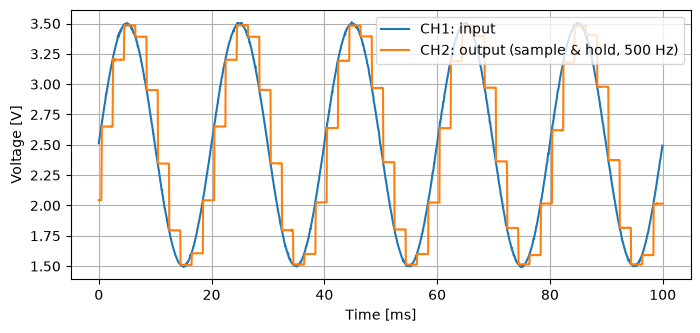

In [3]:
SH_HZ = 500

lab.fg.sine(50, 1.0)
lab.mimic.sample_hold(SH_HZ)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
steps = step_times(t, ch2)
print(f"a new value every {np.median(np.diff(steps)) * 1e3:.2f} ms (1 / {SH_HZ} Hz = {1e3 / SH_HZ:.2f} ms)")
show(t, ch1, ch2, f"sample & hold, {SH_HZ} Hz")

各段の高さは、その段が始まった瞬間の入力の値です。山や谷の近くでは、となりの段とほとんど同じ高さになり、段の変わり目が見えにくいところもあります。

## 実験 2:トラック&ホールド

同じ正弦波を、200 Hz(周期 5 ms)のトラック&ホールドに入れます。周期の半分(2.5 ms)は入力についていき、残りの半分は平らに保つはずです。

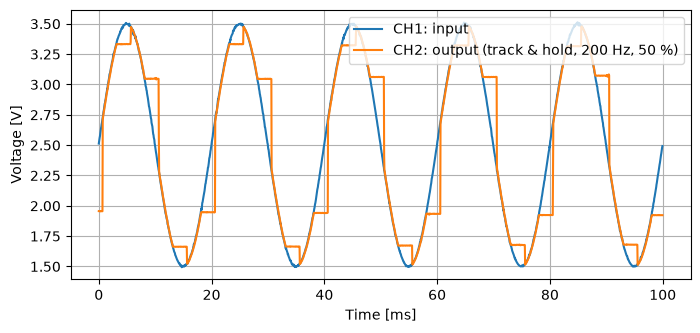

In [4]:
lab.fg.sine(50, 1.0)
lab.mimic.track_hold(200, 0.5)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
show(t, ch1, ch2, "track & hold, 200 Hz, 50 %")

出力は、入力に重なる斜めの部分と、平らな部分を交互にくり返します。サンプル&ホールドは、トラックする時間を一瞬まで短くしたものです。

## 実験 3:エイリアシング

1 kHz の正弦波を、1.1 kHz でサンプル&ホールドします。1 周期に 1.1 回しかつかまえないので、サンプリング定理($f_s > 2f$)を満たしません。つかまえた値をつなぐと、$|1000 - 1100| = 100$ Hz のゆっくりした波に見えるはずです。

sampling 1098.9 Hz: the output is mostly 100.4 Hz (|1000 - 1098.9| = 98.9 Hz)


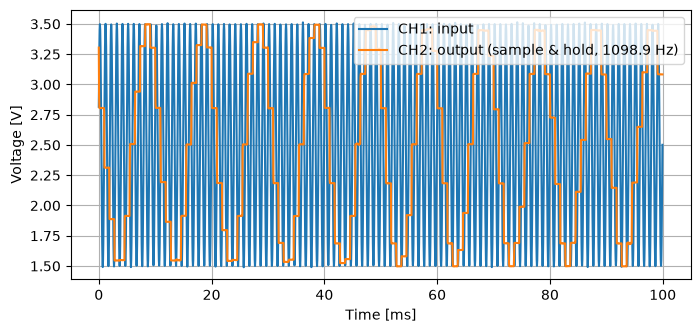

In [5]:
F_IN, SH_HZ = 1000, 1100

lab.fg.sine(F_IN, 1.0)
lab.mimic.sample_hold(SH_HZ)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
fs = real_rate(SH_HZ)
print(f"sampling {fs:.1f} Hz: the output is mostly {main_freq(t, ch2):.1f} Hz "
      f"(|{F_IN} - {fs:.1f}| = {abs(F_IN - fs):.1f} Hz)")
show(t, ch1, ch2, f"sample & hold, {fs:.1f} Hz")

入力(CH1)は 1 kHz で細かく振れているのに、出力(CH2)は 0.1 秒に約 10 回しか上下しない、ゆっくりした階段の波になります。出力だけを見ると、入力が 100 Hz だったのか 1 kHz だったのか区別できません。

見える周波数は、計算より 1 Hz ほどずれることがあります。Arduino(信号発生器)と Mimic(サンプリング)は、それぞれ自分の発振器で動いていて、速さがわずかに(0.1 % 程度)違うからです。見える周波数は 1000 Hz と 1099 Hz の**差**なので、1 kHz の 0.1 % の違いが、99 Hz に対しては 1 % のずれになって現れます。

A/D 変換器の前に、ナイキスト周波数より上を落とすローパスフィルタ(**アンチエイリアシングフィルタ**)を置くのはこのためです。Mimic 自身も入力を 200 kHz でサンプリングしていて、入力にこのフィルタを持っています。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. サンプリング周波数を変える

50 Hz の正弦波を入れたまま、サンプリング周波数を変えて、階段の細かさを見ます。
<details><summary>ヒント</summary>

`SH_HZ` を 200 → 2000 → 100 と変えてみましょう(実験 1 は 500)。1 周期の段の数は $f_s / f$ で、4、40、2 段です。

- 2000 Hz では、ほとんどなめらかな正弦波に見えます。
- 100 Hz(ちょうど $2f$、ナイキスト周波数ぎりぎり)では、1 周期に 2 点しかつかまえないので、方形波のようになります。つかまえる瞬間が山と谷に近いと大きな方形波、0 V を横切るところに近いと小さな方形波(平らに近い)になり、何度か実行すると変わります。

</details>

4.0 steps per period, peak to peak 1.976 V


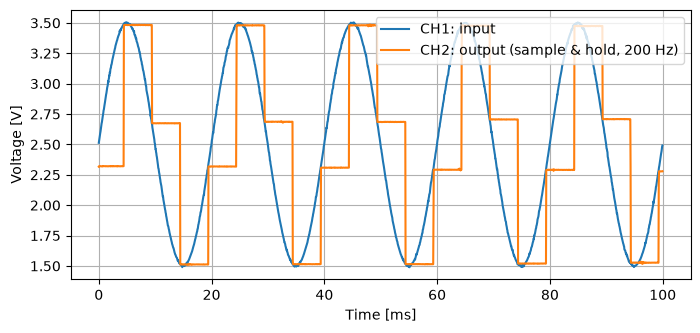

In [6]:
SH_HZ = 200

lab.fg.sine(50, 1.0)
lab.mimic.sample_hold(SH_HZ)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"{real_rate(SH_HZ) / 50:.1f} steps per period, peak to peak {ch2.max() - ch2.min():.3f} V")
show(t, ch1, ch2, f"sample & hold, {SH_HZ} Hz")

### 2. エイリアシングを探す

1 kHz の正弦波を入れたまま、サンプリング周波数を変えて、出力が何 Hz に見えるかを確かめます。
<details><summary>ヒント</summary>

`SH_HZ` を 1050 → 900 → 1000 → 2100 と変えてみましょう(実験 3 は 1100)。出力は、1000 Hz に最も近い $f_s$ の整数倍との差に見えます。

| `SH_HZ` | 見える周波数 |
|---|---|
| 1050 | 約 53 Hz(実際の $f_s$ は 1052.6 Hz) |
| 900 | 約 100 Hz(1000 − 900) |
| 1000 | 0 Hz:毎回同じ位相でつかまえるので、出力はほぼ一定(高さは実行するたびに変わる) |
| 2100 | 1000 Hz のまま($f_s > 2f$ なので正しい周波数。ただし 1 周期に約 2 点の粗い階段) |

周期は 5 µs の整数倍に丸められるので、見える周波数は少しずれます(例:1050 Hz は 190 サンプルで 1052.6 Hz)。

</details>

sampling 1052.6 Hz: output mostly 54.0 Hz (expected 52.6 Hz), peak to peak 1.985 V


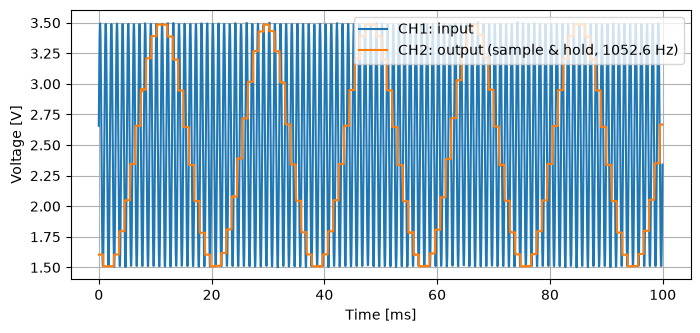

In [7]:
SH_HZ = 1050

lab.fg.sine(1000, 1.0)
lab.mimic.sample_hold(SH_HZ)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
fs = real_rate(SH_HZ)
alias = abs(1000 - round(1000 / fs) * fs)
print(f"sampling {fs:.1f} Hz: output mostly {main_freq(t, ch2):.1f} Hz (expected {alias:.1f} Hz), "
      f"peak to peak {ch2.max() - ch2.min():.3f} V")
show(t, ch1, ch2, f"sample & hold, {fs:.1f} Hz")

### 3. トラックする割合を変える

200 Hz のトラック&ホールドで、周期のうちトラックする割合を変えます。
<details><summary>ヒント</summary>

`RATIO` を 0.1 → 0.9 → 1.0 と変えてみましょう(実験 2 は 0.5)。

- 0.1:ほとんどの時間を保っているので、サンプル&ホールドに近い階段になります。
- 0.9:ほとんどの時間ついていくので、入力にほぼ重なり、ところどころに短い平らな部分ができます。
- 1.0:ずっとついていくので、出力 = 入力になります(バイパスと同じ)。

</details>

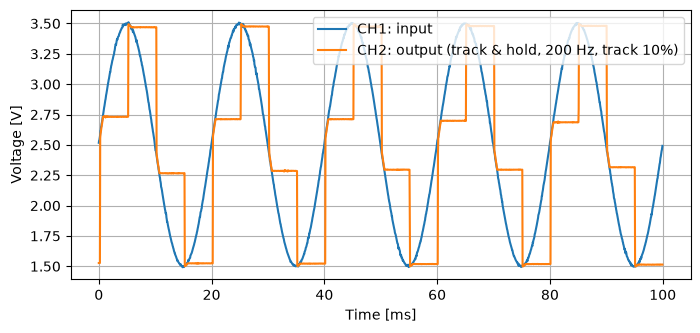

In [8]:
RATIO = 0.1

lab.fg.sine(50, 1.0)
lab.mimic.track_hold(200, RATIO)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
show(t, ch1, ch2, f"track & hold, 200 Hz, track {RATIO:.0%}")

## まとめ

- サンプル&ホールドは、スイッチとコンデンサで入力の瞬間の値をつかまえて保つ。出力は階段になる。トラック&ホールドは、周期の一部のあいだ入力についていく。
- 入力の 1 周期に何回つかまえるか($f_s/f$)で階段の細かさが決まる。$f_s > 2f$(サンプリング定理)を満たさないと、$|f - n f_s|$ の遅い波に化けて見える(エイリアシング)。
- Mimic では `sample_hold(freq)`、`track_hold(freq, ratio)`。周期は 5 µs の整数倍に丸められる。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()